<a href="https://colab.research.google.com/github/Pabloben55/Metodos-Numericos-/blob/main/DIFERENCIAS%20DIVIDIDAS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<H1>
<Font Color="blue"> $DIFERENCIAS$ $DIVIDIDAS$




In [63]:
import sympy as sp #Importamos la libreria

<h4> Calculamos las $diferencias$ $divididas$ ☼

In [64]:
def newton_diferencias_divididas(x, y):
    n = len(x)

    # Creamos la tabla donde se guardaran los resultados
    F = [[0.0 for _ in range(n)] for _ in range(n)]

    # Colocamos los valores iniciales de la funcion
    for i in range(n):
        F[i][0] = y[i]

    # Calculamos las diferencias divididas
    for i in range(1, n):
        for j in range(1, i + 1):
            numerador = F[i][j-1] - F[i-1][j-1]
            denominador = x[i] - x[i-j]
            F[i][j] = numerador / denominador

    # Tomamos los valores de la diagonal principal
    coeficientes = [F[i][i] for i in range(n)]

    return F, coeficientes


<h4>
<font color="red"> $Construimos$ el Polinomio y lo $graficámos$

In [65]:

def construir_y_graficar_polinomio(x_nodos, coeficientes):
    x = sp.Symbol('x')
    n = len(x_nodos)

    # primer coeficiente
    polinomio_newton = coeficientes[0]

    # Terminos del polinomio de Newton
    termino_producto = 1
    for i in range(1, n):
        termino_producto *= (x - x_nodos[i-1])
        polinomio_newton += coeficientes[i] * termino_producto

    # Desarrollamos el polinomio para obtener su forma expandida
    polinomio_expandido = sp.expand(polinomio_newton)

    print("\nPolinomio en forma de Newton:")
    sp.pprint(polinomio_newton)

    print("\nPolinomio desarrollado:")
    sp.pprint(polinomio_expandido)

    rango_x = (x, min(x_nodos) - 0.2, max(x_nodos) + 0.2)

    grafico = sp.plot(
        polinomio_expandido,
        rango_x,
        title="Polinomio de Newton",
        xlabel="x",
        ylabel="p_4(x)",
        line_color="BLUE",
        show=True
    )

    return polinomio_expandido


In [66]:

def evaluar_en_x(x_eval, x_nodos, coeficientes):
    n = len(x_nodos)

    # Iniciamos con el ultimo coeficiente
    resultado = coeficientes[n-1]

    # Calculamos el valor del polinomio usando los coeficientes
    for i in range(n-2, -1, -1):
        resultado = resultado * (x_eval - x_nodos[i]) + coeficientes[i]

    return resultado


<H3> $ EJEMPLO $ $ 1 $
<H5> Construccion de la tabla

In [67]:


x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

# Obtenemos la tabla y los coeficientes
print("--- Tabla de Diferencias Divididas ---")
tabla, coefs = newton_diferencias_divididas(x_datos, y_datos)

# Encabezados de la tabla
encabezado = f"{'xi':<5} | {'f(xi)':<11} | {'1ra Dif':<11} | {'2da Dif':<11} | {'3ra Dif':<11} | {'4ta Dif':<11}"

print(encabezado)
print("-" * len(encabezado))

for i in range(len(x_datos)):
    fila = f"{x_datos[i]:<5.1f} |"

    for j in range(i + 1):
        fila += f" {tabla[i][j]:>10.7f} |"

    print(fila)



--- Tabla de Diferencias Divididas ---
xi    | f(xi)       | 1ra Dif     | 2da Dif     | 3ra Dif     | 4ta Dif    
---------------------------------------------------------------------------
1.0   |  0.7651977 |
1.3   |  0.6200860 | -0.4837057 |
1.6   |  0.4554022 | -0.5489460 | -0.1087339 |
1.9   |  0.2818186 | -0.5786120 | -0.0494433 |  0.0658784 |
2.2   |  0.1103623 | -0.5715210 |  0.0118183 |  0.0680685 |  0.0018251 |


<H5> COEFICIENTES DEL POLINOMIO

In [68]:
print("\nCoeficientes del polinomio")
#lo hacemos pod columnas
for i, c in enumerate(coefs):
    print(f"F_{i},{i} = {c:.7f}")



Coeficientes del polinomio
F_0,0 = 0.7651977
F_1,1 = -0.4837057
F_2,2 = -0.1087339
F_3,3 = 0.0658784
F_4,4 = 0.0018251


<h3>
<font color="green">Gráfica ♠


Polinomio en forma de Newton:
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Polinomio desarrollado:
                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085


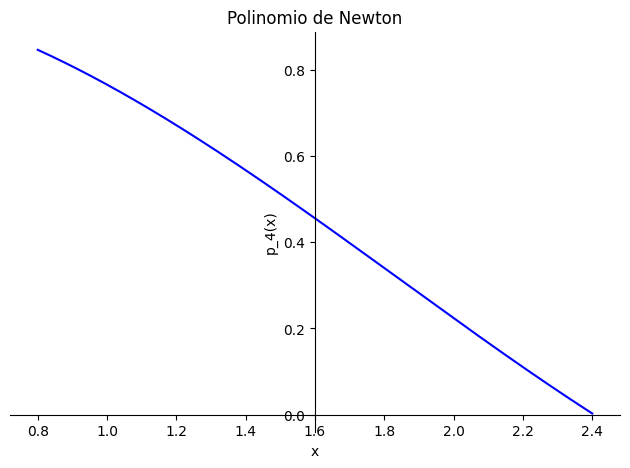

In [69]:

polinomio = construir_y_graficar_polinomio(x_datos, coefs)


<H3>
<FONT color="red"> $Comprobación♥$

In [70]:

# Evaluamos el polinomio en x = 1.5
print("\nComprobación")

x_eval = 1.5
resultado = evaluar_en_x(x_eval, x_datos, coefs)

print(f"P_4({x_eval}) = {resultado:.7f}")
print("Valor esperado en Burden: 0.5118200")



Comprobación
P_4(1.5) = 0.5118200
Valor esperado en Burden: 0.5118200
